# Does Coinbase lead Kraken?

*Price discovery between two bitcoin exchanges, measured second by second over 20 days.
The checks behind it are in the [appendix](appendix.ipynb).*

## Two prices, one bitcoin

Coinbase and Kraken are two exchanges, or *venues*, where people buy and sell bitcoin, and a
bitcoin bought on one is the same bitcoin as one bought on the other. There are no share
classes and no separate legal entities, none of the wrinkles that let Royal Dutch and Shell,
two listed companies with fixed 60/40 claims on one pool of cash flows, trade away from their
own ratio for years at a time. The asset is perfectly fungible, so the law of one price
should hold here more tightly than it ever did in equities.

It does not. Makarov and Schoar (2020) find price gaps between crypto exchanges that are
large, recurrent and slow to close, because closing one takes money already sitting on both
exchanges, and moving money between them is neither fast nor free. The asset is fungible.
The capital is not.

That looseness is what makes the question worth asking. The two prices are tied together in
the long run and free to wander in the short run, which is exactly the setting in which one
venue can move first and the other follow. That is what we mean by one venue *leading* the
other. Why a venue would lead, whether news reaches its traders first or the other venue is
slower to update its quotes, is a separate question, and one that prices alone cannot answer.

We recorded both venues' order books for 20 days to find out whether one of them leads, and
we look at it three ways: by watching the two prices move around each other, by asking
whether one venue's book can forecast the other's price, and by asking which price moves
when the two drift apart.

In [1]:
from datetime import datetime, timezone
from pathlib import Path
import json

import matplotlib as mpl
import matplotlib.pyplot as plt
import numpy as np
import polars as pl
from research.runs import read_oos
from research.validation import confidence_intervals

DATA = next(p for p in (Path("data"), Path("../data")) if p.exists())
real = json.loads((DATA / "record_real.json").read_text(encoding="utf-8"))
prices = pl.read_parquet(DATA / "prices.parquet").sort("ts_ns")

SURFACE, INK, INK2, MUTED = "#fcfcfb", "#0b0b0b", "#52514e", "#898781"
GRID, AXIS = "#e1e0d9", "#c3c2b7"
# One colour per venue, in every chart in this essay.
COINBASE, KRAKEN = "#2a78d6", "#eb6834"

mpl.rcParams.update({
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "savefig.facecolor": SURFACE,
    "axes.edgecolor": AXIS, "axes.labelcolor": INK2, "axes.titlecolor": INK,
    "axes.titlesize": 12, "axes.titleweight": "bold", "axes.titlelocation": "left",
    "axes.titlepad": 12, "axes.labelsize": 10,
    "axes.spines.top": False, "axes.spines.right": False,
    "xtick.color": MUTED, "ytick.color": MUTED, "xtick.labelsize": 9, "ytick.labelsize": 9,
    "grid.color": GRID, "grid.linewidth": 0.8, "legend.frameon": False, "legend.fontsize": 9,
    "figure.dpi": 130, "font.size": 10,
})

## Watching them move

Each exchange keeps an *order book*: every standing offer to buy or sell bitcoin, at the
price each trader named. The highest offer to buy is the *bid*, the lowest offer to sell is
the *ask*, and the gap between them is the *spread*. Halfway between the bid and the ask is
the *mid-price*, and from here on that is what we mean by a venue's price.

We sampled both books once a second over 20 days, keeping only the seconds in which both
books were current.

In [2]:
ts = prices["ts_ns"].to_numpy()
day = prices["date"].to_numpy()
mids = prices.select(["coinbase_mid", "kraken_mid"]).to_numpy()

# A second follows on from the row before it only if no second was dropped in between.
follows = np.r_[False, (np.diff(ts) == 1_000_000_000) & (day[1:] == day[:-1])]
changed = (np.diff(mids, axis=0) != 0)[follows[1:]]
gap = mids[:, 0] - mids[:, 1]
gap_bp = (np.log(mids[:, 0]) - np.log(mids[:, 1])) * 1e4

print(f"{len(prices):,} seconds with both books current, over {len(set(day))} days")
print(f"Coinbase's price changes in {changed[:, 0].mean():.0%} of seconds, "
      f"Kraken's in {changed[:, 1].mean():.0%}")
print(f"Coinbase averages ${-gap.mean():.2f} ({-gap_bp.mean():.2f} bp) below Kraken")

# The text below quotes these.
assert f"{len(prices):,}" == "1,529,334"
assert f"{changed[:, 0].mean():.0%} {changed[:, 1].mean():.0%}" == "33% 13%"
assert f"{-gap.mean():.2f} {-gap_bp.mean():.2f}" == "2.29 0.38"

1,529,334 seconds with both books current, over 20 days
Coinbase's price changes in 33% of seconds, Kraken's in 13%
Coinbase averages $2.29 (0.38 bp) below Kraken


Here are three minutes of it. They were drawn at random from the busiest tenth of minutes,
measured by how far Coinbase's price travelled, so that something is happening in each.

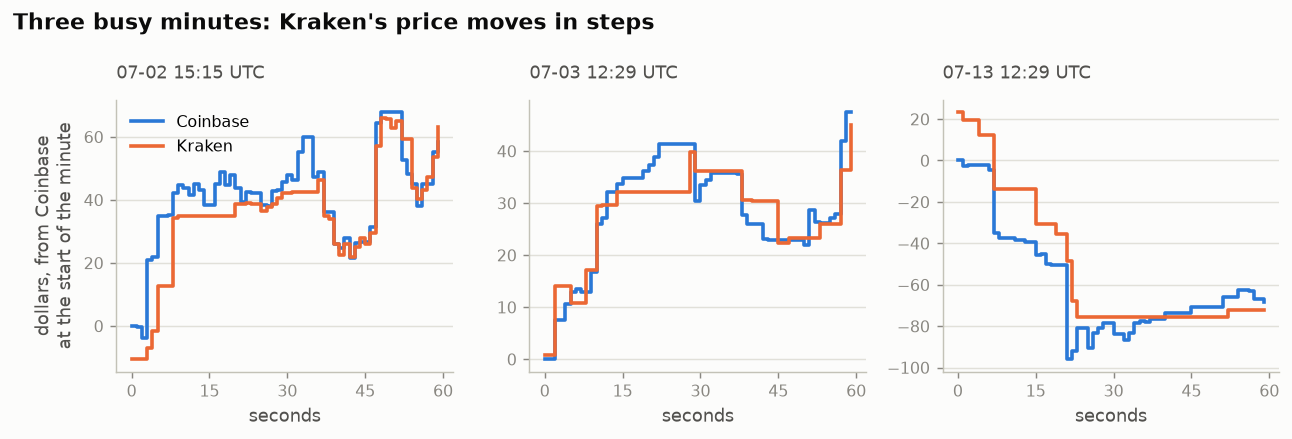

In [3]:
# Whole clock minutes only, so no panel has a missing second in it.
whole = (
    prices.with_columns(minute=pl.col("ts_ns") // 60_000_000_000)
    .filter(pl.len().over("minute") == 60)
)
travel = whole.group_by("minute", maintain_order=True).agg(
    move=(pl.col("coinbase_mid").last() / pl.col("coinbase_mid").first()).log().abs() * 1e4
)
busiest = travel.filter(pl.col("move") > pl.col("move").quantile(0.9))["minute"].to_numpy()
picked = np.sort(np.random.default_rng(1).choice(busiest, 3, replace=False))

fig, axes = plt.subplots(1, 3, figsize=(10, 3.4))
for ax, minute in zip(axes, picked):
    w = whole.filter(pl.col("minute") == minute)
    second = (w["ts_ns"].to_numpy() - w["ts_ns"][0]) / 1e9
    start = w["coinbase_mid"][0]
    for venue, colour in (("coinbase", COINBASE), ("kraken", KRAKEN)):
        ax.step(second, w[f"{venue}_mid"] - start, where="post", color=colour, lw=2,
                label=venue.capitalize())
    when = datetime.fromtimestamp(w["ts_ns"][0] / 1e9, tz=timezone.utc)
    ax.set_title(when.strftime("%m-%d %H:%M UTC"), fontsize=10, color=INK2, fontweight="normal")
    ax.set_xticks([0, 15, 30, 45, 60])
    ax.set_xlabel("seconds")
    ax.grid(axis="y", zorder=0)
axes[0].set_ylabel("dollars, from Coinbase\nat the start of the minute")
axes[0].legend(loc="upper left")
fig.suptitle("Three busy minutes: Kraken's price moves in steps", x=0.01, ha="left",
             fontsize=12, fontweight="bold", color=INK)
fig.tight_layout()
plt.show()

Two things are visible straight away. The prices are not identical: across the 20 days,
Coinbase averages \$2.29, or 0.38 basis points, below Kraken. (A basis point is a hundredth
of a percent.) And they do not move alike. Coinbase's price changes in 33% of seconds,
Kraken's in 13%, so Kraken's line is a staircase, flat for stretches and then stepping,
often just after Coinbase has moved.

Often, not always. In the middle minute Kraken steps first. Three minutes are an anecdote,
and the next section replaces them with an average over all of them.

## One follows the other

To see the pattern we line up every moment one venue's price jumped and average what both
prices did around it.

A *jump* here is a move of at least 2 basis points in a single second. For each jump we
measure both prices from where they stood the second before, flip falling jumps so that
every jump points up, and average from ten seconds before to fifteen after.

In [4]:
JUMP_BP, BEFORE, AFTER = 2.0, 10, 15
offsets = np.arange(-BEFORE, AFTER + 1)
logp = np.log(mids) * 1e4               # in basis points, so differences are moves in bp
stretch = np.cumsum(~follows)           # rows sharing a number are one unbroken run


def around_jumps(venue):
    """Both prices around every jump at one venue, from where each stood the second
    before, flipped so the jump points up. Returns the jump rows and their paths."""
    move = np.r_[np.nan, np.diff(logp[:, venue])]
    at = np.flatnonzero(follows & (np.abs(move) >= JUMP_BP))
    at = at[(at >= BEFORE) & (at + AFTER < len(logp))]
    at = at[stretch[at - BEFORE] == stretch[at + AFTER]]  # no missing second in the window
    paths = logp[at[:, None] + offsets] - logp[at - 1][:, None, :]
    return at, paths * np.sign(move[at])[:, None, None]


now, later = BEFORE, BEFORE + 10  # where the jump second, and ten seconds on, sit in a path
jumps = {"Coinbase": around_jumps(0), "Kraken": around_jumps(1)}
for venue, (at, _) in jumps.items():
    print(f"{venue:9s} {len(at):,} jumps of at least {JUMP_BP:g} bp")
print(f"{JUMP_BP:g} bp at the median price, ${np.median(mids[:, 0]):,.0f}, "
      f"is ${np.median(mids[:, 0]) * JUMP_BP / 1e4:.0f}")

at, paths = jumps["Coinbase"]
mean = paths.mean(axis=0)
by_day = [paths[day[at] == d][:, later].mean(axis=0) for d in sorted(set(day))]
covered = [k / c for c, k in by_day]
print(f"\nwhen Coinbase jumps, in the same second: Coinbase {mean[now, 0]:.2f} bp, "
      f"Kraken {mean[now, 1]:.2f} bp")
print(f"ten seconds on, Kraken has covered {mean[later, 1] / mean[later, 0]:.0%} "
      f"of Coinbase's move ({min(covered):.0%} to {max(covered):.0%} by day)")

at, paths = jumps["Kraken"]
mean = paths.mean(axis=0)
run_up = [-paths[day[at] == d][:, 0, 0].mean() for d in sorted(set(day))]
print(f"\nwhen Kraken jumps, from ten seconds before to the second before: "
      f"Coinbase rose {-mean[0, 0]:.2f} bp, Kraken {-mean[0, 1]:.2f} bp")
print(f"  Coinbase's run-up by day: {min(run_up):.2f} to {max(run_up):.2f} bp")
print(f"in the same second: Kraken {mean[now, 1]:.2f} bp, Coinbase {mean[now, 0]:.2f} bp; "
      f"over the next ten, Coinbase {mean[later, 0] - mean[now, 0]:.2f} bp more")

# The text below quotes these.
c, k = jumps["Coinbase"][1].mean(axis=0), mean
assert f"{c[now, 0]:.2f} {c[now, 1]:.2f} {c[later, 1] / c[later, 0]:.0%}" == "3.07 1.50 91%"
assert f"{min(covered):.0%} {max(covered):.0%}" == "69% 96%"
assert f"{-k[0, 0]:.2f} {-k[0, 1]:.2f} {k[later, 0] - k[now, 0]:.2f}" == "2.20 0.74 0.29"
assert min(run_up) > 0

Coinbase  22,446 jumps of at least 2 bp
Kraken    23,835 jumps of at least 2 bp
2 bp at the median price, $62,780, is $13



when Coinbase jumps, in the same second: Coinbase 3.07 bp, Kraken 1.50 bp
ten seconds on, Kraken has covered 91% of Coinbase's move (69% to 96% by day)



when Kraken jumps, from ten seconds before to the second before: Coinbase rose 2.20 bp, Kraken 0.74 bp
  Coinbase's run-up by day: 0.93 to 2.59 bp
in the same second: Kraken 3.04 bp, Coinbase 1.61 bp; over the next ten, Coinbase 0.29 bp more


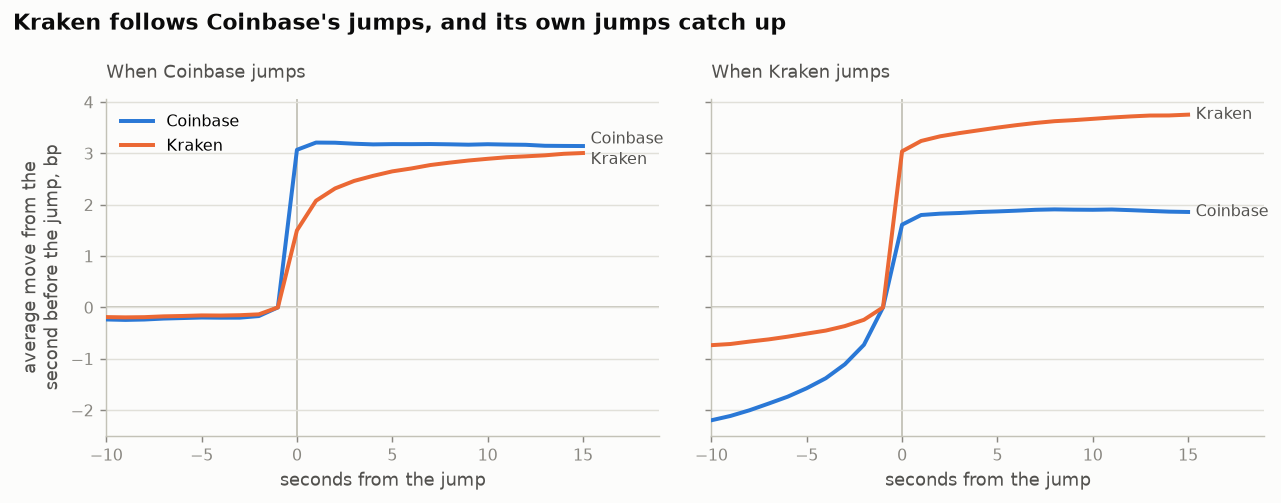

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(10, 3.9), sharey=True)
for ax, (jumper, (_, paths)) in zip(axes, jumps.items()):
    mean = paths.mean(axis=0)
    ax.axvline(0, color=AXIS, lw=1, zorder=1)
    ax.axhline(0, color=AXIS, lw=1, zorder=1)
    # Where the lines end, pushed apart when they finish too close to read both labels.
    ends = mean[-1].copy()
    if abs(ends[0] - ends[1]) < 0.4:
        middle, above = ends.mean(), ends[0] >= ends[1]
        ends = middle + np.array([0.2, -0.2] if above else [-0.2, 0.2])
    for i, (venue, colour) in enumerate((("Coinbase", COINBASE), ("Kraken", KRAKEN))):
        ax.plot(offsets, mean[:, i], color=colour, lw=2.2, label=venue, zorder=4)
        ax.text(AFTER + 0.4, ends[i], venue, va="center", fontsize=9, color=INK2)
    ax.set_title(f"When {jumper} jumps", fontsize=10, color=INK2, fontweight="normal")
    ax.set_xlabel("seconds from the jump")
    ax.set_xlim(-BEFORE, AFTER + 4)
    ax.grid(axis="y", zorder=0)
axes[0].set_ylabel("average move from the\nsecond before the jump, bp")
axes[0].legend(loc="upper left")
fig.suptitle("Kraken follows Coinbase's jumps, and its own jumps catch up", x=0.01,
             ha="left", fontsize=12, fontweight="bold", color=INK)
fig.tight_layout()
plt.show()

The two panels are not mirror images, and the difference between them is the result.

When Coinbase jumps (left), little has happened beforehand at either venue. Kraken moves
1.50 bp in the same second, against Coinbase's 3.07, and then keeps moving: ten seconds on it
has covered 91% of Coinbase's move. Day by day that figure runs from 69% to 96%.

When Kraken jumps (right), the action starts before the jump. From ten seconds before it to
the second before it, Coinbase rose 2.20 bp in the direction Kraken is about to go, against
0.74 bp for Kraken itself, and the run-up is there on every one of the 20 days. Once Kraken
has jumped, Coinbase barely moves: 0.29 bp more over the next ten seconds. On average, a
Kraken jump is Kraken catching up.

Both panels share one blind spot. In the jump second itself both prices move, and one-second
bars cannot say which moved first inside it. We will meet that second again.

## Can Coinbase forecast Kraken?

If Kraken follows Coinbase, then what is happening at Coinbase now should say something about
where Kraken's price goes next. We can test that directly, by building a forecast and scoring
it on days it never saw.

The forecast predicts how far Kraken's price moves over the next five seconds, and it is
allowed to look only at Coinbase: Coinbase's spread, how much is on offer near the best
prices on each side, how lopsided the recent buying and selling has been, and how its price
has moved lately. Nothing from Kraken goes in, so the forecast cannot simply extend Kraken's
own recent moves. The model is gradient boosting, a standard method that fits many small
decision trees, each correcting the errors of the ones before it.

We score it against the simplest forecast there is, that the price will not move:

$$
R^2 = 1 - \frac{\sum_t (y_t - \hat{y}_t)^2}{\sum_t y_t^2}
$$

Here $y_t$ is Kraken's actual five-second move and $\hat{y}_t$ is the forecast. Zero means no
better than predicting no change, and one would be perfect.

The forecast is scored the way it would have had to be used: trained only on earlier days
and tested on the days after, across four rounds that between them test 12 of the 20 days.
The range given with each score comes from resampling whole test days, so it reflects how
much the result varies from one day to the next. Then we run the whole thing again in the
other direction, forecasting Coinbase from Kraken alone, with nothing else changed.

In [6]:
forecasts = {
    "Coinbase to Kraken": read_oos(pl.read_parquet(DATA / "oos_real.parquet"))["gbt"],
    "Kraken to Coinbase": read_oos(pl.read_parquet(DATA / "oos_reverse.parquet"))["gbt"],
}
scores = {direction: confidence_intervals(o) for direction, o in forecasts.items()}
print(f"{len(real['folds'])} rounds, {real['n_test_dates']} test days\n")
for direction, s in scores.items():
    (r2, low, high), hit = s["r2_vs_zero"], s["hit_rate"][0]
    print(f"{direction}: R2 {r2:.3f} [{low:.3f}, {high:.3f}], "
          f"direction right on {hit:.0%} of moves")
forward, backward = (scores[d]["r2_vs_zero"][0] for d in forecasts)
print(f"the forward R2 is {forward / backward:.1f} times the reverse")
y = forecasts["Coinbase to Kraken"].y
print(f"always guessing 'up' would be right on {(y[y != 0] > 0).mean():.0%} of Kraken's moves")


def r2_by_day(o):
    """R2 against no change, one test day at a time."""
    return {d: 1 - ((o.y - o.pred)[o.dates == d] ** 2).sum() / (o.y[o.dates == d] ** 2).sum()
            for d in np.unique(o.dates)}


by_day = {direction: r2_by_day(o) for direction, o in forecasts.items()}
test_days = sorted(by_day["Coinbase to Kraken"])
ahead = [by_day["Coinbase to Kraken"][d] / by_day["Kraken to Coinbase"][d] for d in test_days]
print(f"\nforward ahead on {sum(a > 1 for a in ahead)} of {len(test_days)} test days, "
      f"by {min(ahead):.1f} to {max(ahead):.1f} times")

# The text below quotes these.
fwd, rev = scores["Coinbase to Kraken"], scores["Kraken to Coinbase"]
assert "{:.3f} {:.3f} {:.3f}".format(*fwd["r2_vs_zero"]) == "0.103 0.091 0.112"
assert "{:.3f} {:.3f} {:.3f}".format(*rev["r2_vs_zero"]) == "0.011 0.008 0.014"
assert f"{fwd['hit_rate'][0]:.0%} {rev['hit_rate'][0]:.0%} {forward / backward:.1f}" == "76% 58% 9.6"
assert f"{(y[y != 0] > 0).mean():.0%} {min(ahead):.1f}" == "51% 3.4" and min(ahead) > 1

4 rounds, 12 test days

Coinbase to Kraken: R2 0.103 [0.091, 0.112], direction right on 76% of moves
Kraken to Coinbase: R2 0.011 [0.008, 0.014], direction right on 58% of moves
the forward R2 is 9.6 times the reverse
always guessing 'up' would be right on 51% of Kraken's moves



forward ahead on 12 of 12 test days, by 3.4 to 19.5 times


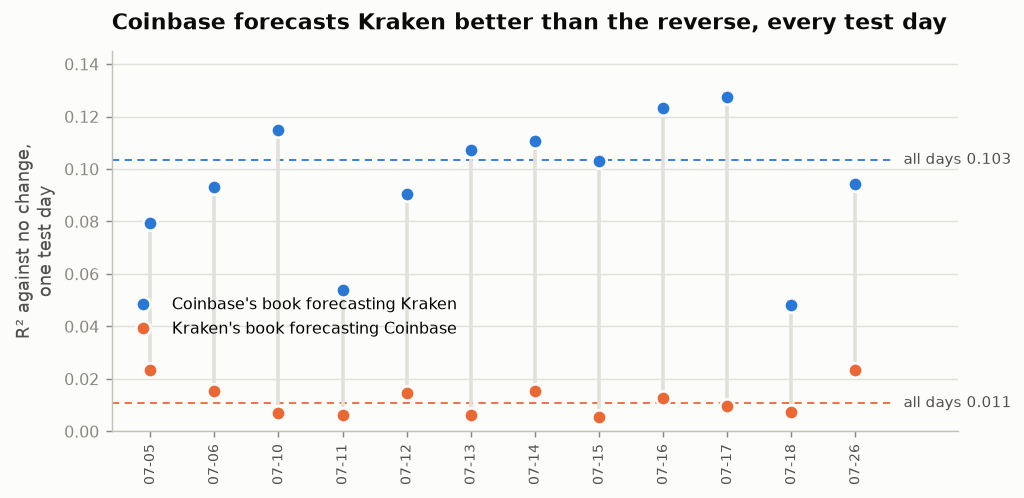

In [7]:
fig, ax = plt.subplots(figsize=(8.4, 3.8))
x = np.arange(len(test_days))
sources = (("Coinbase to Kraken", COINBASE, "Coinbase's book forecasting Kraken"),
           ("Kraken to Coinbase", KRAKEN, "Kraken's book forecasting Coinbase"))
ax.vlines(x, *([by_day[d][t] for t in test_days] for d, _, _ in sources),
          color=GRID, lw=2, zorder=2)
for direction, colour, label in sources:
    ax.plot(x, [by_day[direction][t] for t in test_days], "o", color=colour, ms=8,
            mec=SURFACE, mew=1.5, label=label, zorder=4)
    pooled = scores[direction]["r2_vs_zero"][0]
    # Stopped short of the right edge, so the label can sit at its end.
    ax.hlines(pooled, -0.6, len(test_days) - 0.4, color=colour, lw=1, ls=(0, (4, 3)),
              zorder=1)
    ax.text(len(test_days) - 0.25, pooled, f"all days {pooled:.3f}", va="center",
            fontsize=8.5, color=INK2)
ax.set_xticks(x, [t[5:] for t in test_days], rotation=90, color=INK2, fontsize=8)
ax.set_xlim(-0.6, len(test_days) + 0.6)
ax.set_ylim(0, 0.145)
ax.set_ylabel("R² against no change,\none test day")
ax.set_title("Coinbase forecasts Kraken better than the reverse, every test day")
ax.grid(axis="y", zorder=0)
ax.legend(loc="center left", bbox_to_anchor=(0, 0.3))
plt.show()

Coinbase's book forecasts Kraken's next five seconds with an R² of 0.103, in a range of 0.091
to 0.112: about a tenth of the squared movement, on days the model never trained on. Put
more plainly, counting only the five-second stretches in which Kraken's price moved, the
forecast got the direction right 76% of the time, where always guessing "up" would have
managed 51%. None of this is a trading result: the forecast is of the mid-price, and it
ignores fees, the spread, and whether an order would have been filled.

The other way round, Kraken's book forecasts Coinbase with an R² of 0.011 (0.008 to 0.014),
right on 58% of moves. The forward direction is 9.6 times the reverse overall, and it is
ahead on every one of the 12 test days, by at least 3.4 times.

## Who closes the gap?

The jump charts and the forecast agree that Coinbase's price moves first and Kraken's
catches up. The literature on price discovery has its own tool for the same question, far
simpler than a gradient-boosted forecast, and it adds something neither of the others gives:
how much of the lasting change in the price starts at each venue.

It starts from the tie between the two prices. Arbitrage keeps them close but not equal.
They drift apart for a moment and then come back together. When they part, which one moves
to close the gap?

Write $p^C_t$ and $p^K_t$ for the log of each venue's mid-price at second $t$ (logs, so that
a gap between them is a percentage rather than a dollar amount), and $\Delta p_t$ for how far
a price moved in that second. Then fit one regression per venue:

$$
\Delta p^K_t = \mu_K + a_K\,(p^C_{t-1} - p^K_{t-1}) + \sum_{k=1}^{10}\big(b_k\,\Delta p^C_{t-k} + c_k\,\Delta p^K_{t-k}\big) + \varepsilon^K_t
$$

$$
\Delta p^C_t = \mu_C + a_C\,(p^K_{t-1} - p^C_{t-1}) + \sum_{k=1}^{10}\big(b'_k\,\Delta p^C_{t-k} + c'_k\,\Delta p^K_{t-k}\big) + \varepsilon^C_t
$$

The sum is the last ten seconds of both prices' moves. It is there to absorb momentum, so
that none of it gets credited to the gap term, which is the one we care about. The constant
$\mu$ lets the gap's usual level be something other than zero. That matters here, since
Coinbase averages \$2.29 below Kraken, and a pull should be measured toward where the gap
normally sits. Each equation measures the gap from its own venue's side, so $a_K$ and $a_C$
are the same kind of number: the share of the gap to the other venue that a venue closes in
the next second. A venue that sets the price should have $a$ near zero, because it has
nothing to catch up to. A venue that follows should have $a$ clearly above zero.

The pair of equations is a *vector error-correction model*, the standard tool for two prices
that wander but stay tied together. Fitting it takes nothing more than least squares, so we
fit it ourselves, separately on each of the 20 days. We use only the seconds whose ten
seconds before were all kept: across a stretch of dropped seconds the two prices on either
side can be minutes apart, and the move between them is not a one-second move.

In [8]:
def fit_day(p, whole, lags=10):
    """Least squares for one day's pair of equations. `p` is that day's log prices, one
    row per second, Coinbase then Kraken, and `whole` marks the rows that follow on from
    the row before with no second dropped. Returns each venue's pull and the surprises."""
    dp = np.diff(p, axis=0)                    # each move, from one row to the next
    gap = p[:-1, 0] - p[:-1, 1]                # Coinbase minus Kraken, before each move
    # A move is used only if it and the ten before it each span exactly one second.
    stretch = np.cumsum(~whole)
    t = np.arange(lags, len(dp))
    t = t[stretch[t - lags] == stretch[t + 1]]
    X = np.column_stack([gap[t], *(dp[t - k] for k in range(1, lags + 1)), np.ones(len(t))])
    coef, *_ = np.linalg.lstsq(X, dp[t], rcond=None)
    surprises = dp[t] - X @ coef
    # One set of regressors serves both equations. Its gap is Coinbase minus Kraken, which
    # is Kraken's side of it; Coinbase's own side is the negative, so its pull flips sign.
    return np.array([-coef[0, 0], coef[0, 1]]), surprises


def by_day(step=1):
    """Each day's log prices on bars `step` seconds apart, and which bars follow on."""
    for (d,), g in prices.group_by(["date"], maintain_order=True):
        g = g.filter(pl.col("ts_ns") % (step * 1_000_000_000) == 0)
        whole = np.r_[False, np.diff(g["ts_ns"].to_numpy()) == step * 1_000_000_000]
        yield d, np.log(g.select(["coinbase_mid", "kraken_mid"]).to_numpy()), whole


fits = {d: fit_day(p, whole) for d, p, whole in by_day()}
dates = [d[5:] for d in fits]
pulls = np.array([a for a, _ in fits.values()])
closes = {"Coinbase": pulls[:, 0], "Kraken": pulls[:, 1]}
used = sum(len(e) for _, e in fits.values())
moves = sum(len(p) - 11 for _, p, _ in by_day())
print(f"fitted {len(fits)} days on {used:,} one-second moves, leaving out the "
      f"{moves - used:,} ({1 - used / moves:.1%}) with a dropped second in their last ten\n")

for venue, a in closes.items():
    print(f"{venue:9s} closes {a.mean():.2%} of the gap a second on average "
          f"(daily range {a.min():.2%} to {a.max():.2%})")
ratio = closes["Kraken"].mean() / closes["Coinbase"].mean()
print(f"\nKraken pulls {ratio:.0f} times as hard as Coinbase, on average")
print(f"Kraken's pull is above zero on {(closes['Kraken'] > 0).sum()} of {len(fits)} days")
print(f"Coinbase's is below zero on {(closes['Coinbase'] < 0).sum()} of {len(fits)} days")

# The text below quotes these. If the data changes, this fails before the text goes stale.
assert f"{closes['Kraken'].mean():.2%} {closes['Coinbase'].mean():.2%} {ratio:.0f}" == "4.55% 0.27% 17"
assert f"{closes['Coinbase'].min():.2%}" == "-0.09%"
assert (closes["Kraken"] > 0).sum() == 20 and (closes["Coinbase"] < 0).sum() == 4

fitted 20 days on 1,490,818 one-second moves, leaving out the 38,296 (2.5%) with a dropped second in their last ten

Coinbase  closes 0.27% of the gap a second on average (daily range -0.09% to 1.26%)
Kraken    closes 4.55% of the gap a second on average (daily range 1.08% to 8.31%)

Kraken pulls 17 times as hard as Coinbase, on average
Kraken's pull is above zero on 20 of 20 days
Coinbase's is below zero on 4 of 20 days


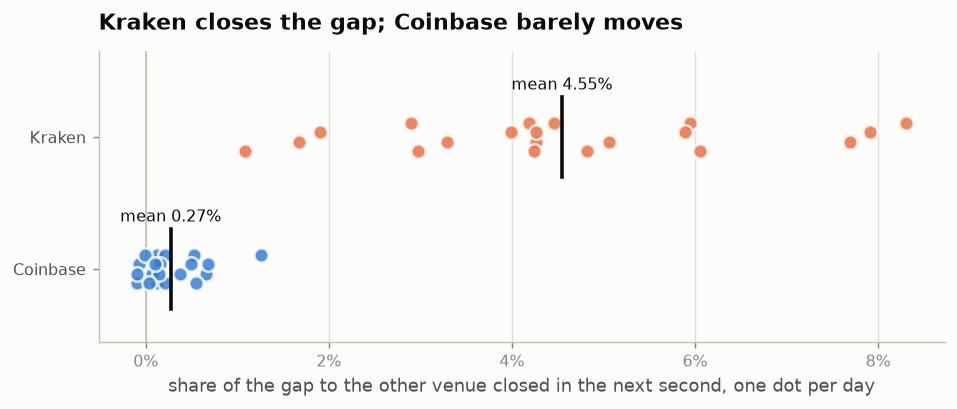

In [9]:
fig, ax = plt.subplots(figsize=(8.4, 2.9))
for row, (venue, colour) in enumerate([("Coinbase", COINBASE), ("Kraken", KRAKEN)]):
    a = closes[venue]
    # Spread the dots a little vertically, in rank order, so close days stay visible.
    lift = (np.argsort(np.argsort(a)) % 4 - 1.5) * 0.07
    ax.plot(a, row + lift, "o", color=colour, ms=8, alpha=0.8, mec=SURFACE, mew=1.5, zorder=4)
    ax.plot([a.mean()] * 2, [row - 0.3, row + 0.3], color=INK, lw=2, zorder=5)
    ax.text(a.mean(), row + 0.36, f"mean {a.mean():.2%}", ha="center", fontsize=9, color=INK)
ax.axvline(0, color=AXIS, lw=1)
ax.set_yticks([0, 1], ["Coinbase", "Kraken"], color=INK2)
ax.xaxis.set_major_formatter(mpl.ticker.PercentFormatter(1.0, decimals=0))
ax.set_xlabel("share of the gap to the other venue closed in the next second, one dot per day")
ax.set_title("Kraken closes the gap; Coinbase barely moves")
ax.set_ylim(-0.55, 1.65)
ax.grid(axis="x", zorder=0)
plt.show()

Kraken closes 4.55% of the gap each second on average, and its pull is above zero on all 20
days. Coinbase closes 0.27%, so Kraken pulls 17 times as hard. Coinbase's pull is so close
to zero that on 4 of the 20 days its estimate dips just below it, to -0.09% at the lowest.

Coinbase barely chases Kraken. Kraken chases Coinbase.

### Whose news sticks?

Knowing who chases tells us which price is the anchor. The standard measure in this
literature, Hasbrouck's *information share*, goes one step further and asks whose news lasts.

Each second, each price takes a surprise: the $\varepsilon$ in the equations, the part of the
move that neither the gap nor the last ten seconds predicted. Some surprises are undone
within seconds. The rest permanently move the price both venues share. The information share
is the fraction of that permanent movement that started at each venue.

The two pull-backs are enough to say how much each surprise counts. A Coinbase surprise
lasts to the extent that Kraken chases it, and a Kraken surprise to the extent that Coinbase
does:

$$
\text{permanent move}_t \;\propto\; a_K\,\varepsilon^C_t + a_C\,\varepsilon^K_t
$$

If the two surprises were unrelated, Coinbase's share would follow directly, with $\sigma$
for the typical size of each venue's surprise:

$$
\text{IS}_C = \frac{a_K^2\,\sigma_C^2}{a_K^2\,\sigma_C^2 + a_C^2\,\sigma_K^2}
$$

They are not unrelated. This is the blind spot from the jump charts: when both books move
inside the same second, the data cannot say which moved first, and that overlap could belong
to either venue. So the share is computed twice, once crediting the overlap to Coinbase and
once to Kraken, and reported as the range between the two. The width of the range is exactly
how much the data cannot resolve.

Crediting the overlap to one venue is what a Cholesky factorization does, if that venue is
put first.

In [10]:
def coinbase_share(pulls, surprises):
    """Coinbase's information share as a (low, high) range, and how correlated the two
    venues' surprises were."""
    omega = np.cov(surprises, rowvar=False)
    weight = np.array([pulls[1], pulls[0]])    # Coinbase's surprise counts by Kraken's pull
    total = weight @ omega @ weight
    shares = []
    for order in ([0, 1], [1, 0]):
        # The factor splits the two surprises into all of the first venue's, and only what
        # the second adds beyond it, so whichever venue goes first is credited the overlap.
        factor = np.linalg.cholesky(omega[np.ix_(order, order)])
        piece = (weight[order] @ factor) ** 2 / total
        shares.append(piece[order.index(0)])
    return sorted(shares), omega[0, 1] / np.sqrt(omega[0, 0] * omega[1, 1])


shares = [coinbase_share(a, e) for a, e in fits.values()]
bounds = np.array([b for b, _ in shares])
corr = np.array([c for _, c in shares])
widest = int(bounds[:, 0].argmin())

# The same fit on bars thirty seconds apart instead.
shares_30 = [coinbase_share(*fit_day(p, whole)) for _, p, whole in by_day(30)]
bounds_30 = np.array([b for b, _ in shares_30])
corr_30 = np.array([c for _, c in shares_30])

print(f"Coinbase's information share, one-second bars, {len(fits)} days")
print(f"  range averaged over the days  [{bounds[:, 0].mean():.3f}, {bounds[:, 1].mean():.3f}]")
print(f"  widest day                    {dates[widest]}: "
      f"[{bounds[widest, 0]:.3f}, {bounds[widest, 1]:.3f}]")
print(f"  surprise correlation          {corr.mean():.2f} on average, "
      f"{corr[widest]:.2f} on {dates[widest]}, the highest of any day")
print(f"\nthirty-second bars instead: range averaged over the days "
      f"[{bounds_30[:, 0].mean():.3f}, {bounds_30[:, 1].mean():.3f}], "
      f"surprise correlation {corr_30.mean():.2f} on average")

# Quoted in the text below.
assert corr.argmax() == widest
assert f"[{bounds[:, 0].mean():.3f}, {bounds[:, 1].mean():.3f}]" == "[0.754, 0.997]"
assert f"{dates[widest]} [{bounds[widest, 0]:.3f}, {bounds[widest, 1]:.3f}]" == "06-29 [0.545, 0.992]"
assert f"{corr.mean():.2f} {corr[widest]:.2f}" == "0.46 0.61"
assert f"{bounds_30[:, 0].mean():.3f} {bounds_30[:, 1].mean():.3f} {corr_30.mean():.2f}" == \
    "0.237 0.983 0.89"

Coinbase's information share, one-second bars, 20 days
  range averaged over the days  [0.754, 0.997]
  widest day                    06-29: [0.545, 0.992]
  surprise correlation          0.46 on average, 0.61 on 06-29, the highest of any day

thirty-second bars instead: range averaged over the days [0.237, 0.983], surprise correlation 0.89 on average


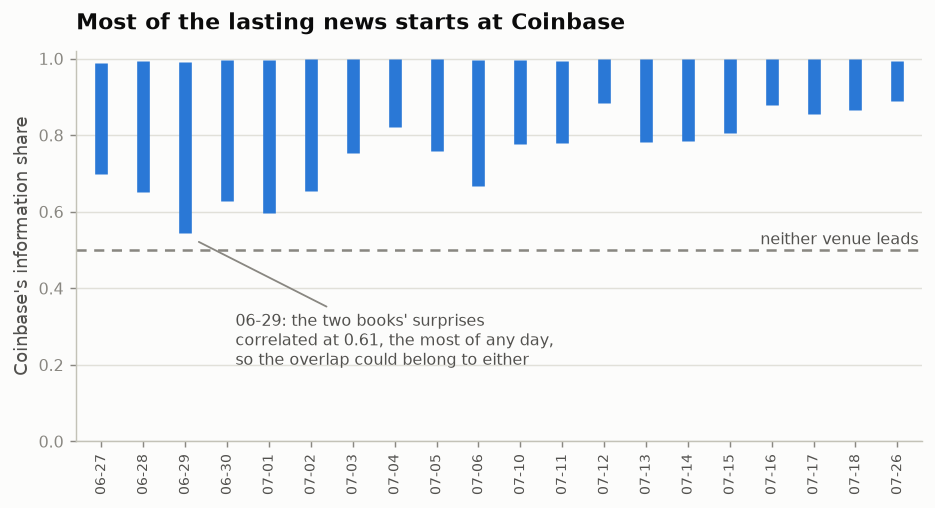

In [11]:
fig, ax = plt.subplots(figsize=(8.4, 3.9))
x = np.arange(len(fits))
for i, (low, high) in enumerate(bounds):
    ax.plot([i, i], [low, high], color=COINBASE, lw=7, solid_capstyle="butt", zorder=4)
ax.axhline(0.5, color=MUTED, lw=1.4, ls=(0, (4, 3)), zorder=2)
ax.text(len(fits) - 0.5, 0.515, "neither venue leads", ha="right", fontsize=9,
        color=INK2)
ax.annotate(f"{dates[widest]}: the two books' surprises\ncorrelated at {corr[widest]:.2f}, "
            f"the most of any day,\nso the overlap could belong to either",
            xy=(widest + 0.25, bounds[widest, 0] - 0.02), xytext=(widest + 1.2, 0.2),
            ha="left", fontsize=9, color=INK2,
            arrowprops=dict(arrowstyle="-", color=MUTED, lw=1))
ax.set_xticks(x, dates, rotation=90, color=INK2, fontsize=8)
ax.set_xlim(-0.6, len(fits) - 0.4)
ax.set_ylim(0, 1.02)
ax.set_ylabel("Coinbase's information share")
ax.set_title("Most of the lasting news starts at Coinbase")
ax.grid(axis="y", zorder=0)
plt.show()

On a typical day the range sits far above one half, the line where neither venue leads.
Averaged over the 20 days it runs from 0.754 to 0.997.

The range is widest on the day the two venues' surprises overlapped most. On 06-29 they
correlated at 0.61, against 0.46 on average, so more of each second's news landed on both
books at once and the data could not say where it started. The range that day runs from
0.545 to 0.992, so even its lower end is above one half.

These are one-second bars, and the answer depends on that. Sample every thirty seconds
instead and both venues have caught up with any news by the time we look: their surprises
correlate at 0.89 rather than 0.46, and the range averaged over the days widens to 0.237 to
0.983.

## What it adds up to

Three different looks at the same 20 days agree. When Coinbase's price jumps, Kraken's
follows, covering 91% of the move within ten seconds, and when Kraken's jumps, Coinbase's has
usually moved already. Coinbase's order book forecasts Kraken's next five seconds 9.6 times
better than the reverse, on days the model never saw. And when the two prices drift apart,
Kraken pulls 17 times as hard as Coinbase to close the gap, so most of the lasting change in
the price starts at Coinbase: a share between 0.754 and 0.997, averaged over the days. At
one-second resolution, price moves at Coinbase first and Kraken follows.

The law of one price holds in the end. What these 20 days measure is which side does the
moving.

The checks a referee would want are in the [appendix](appendix.ipynb):
how the forecast was validated and tested against looking good by accident, how well its
sizes are calibrated, how its accuracy rises when it calls only its most confident moves, how
the information share holds up to holes in the recording, to its settings and to the clock
the prices are timed by, and every published number recomputed from the committed files.

**Data and code.** The prices, predictions and run records in `data/` were exported from
[crosstick](https://github.com/ryanp2718/crosstick) at commit `fb7a22d`, which is also the
commit this notebook installs its analysis code from. Capture, order-book reconstruction,
the feature build and the forecast all live there.

**References.** Makarov and Schoar, "Trading and arbitrage in cryptocurrency markets",
Journal of Financial Economics 135(2), 2020. Hasbrouck, "One security, many markets:
determining the contributions to price discovery", Journal of Finance 50(4), 1995. Froot and
Dabora, "How are stock prices affected by the location of trade?", Journal of Financial
Economics 53(2), 1999.